# Minimum Proficiency Risk: Preprocessing Pipeline and Diagnostics

**Author:** Gentille Uwera

Preprocessing of the PASEC2019 Grade 6 data for a classifier that flags students likely to be below the PASEC
minimum proficiency level in mathematics. Every step that learns from data is fitted on `X_train` only.

## 0. Setup

The notebook runs in Google Colab or locally. scikit-learn is pinned to 1.9.1 because earlier versions assign schools to folds differently, which changes the split.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/GentilleUwera/pasec-minimum-proficiency-risk.git"
DRIVE_ZIP = "/content/drive/MyDrive/PASEC2019/PASEC2019_INT_STATA.zip"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/pasec-minimum-proficiency-risk").exists():
        !git clone -q {REPO_URL} /content/pasec-minimum-proficiency-risk
    os.chdir("/content/pasec-minimum-proficiency-risk")
    !pip install -q "scikit-learn==1.9.1" "xgboost==3.4.1" "catboost==1.2.10" missingno
    if not Path("data/raw/PASEC2019_INT_STATA.zip").exists():
        !cp "{DRIVE_ZIP}" data/raw/
else:
    root = Path.cwd()
    while not (root / "src").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)

sys.path.insert(0, os.getcwd())
print("Repository root:", Path.cwd().name)
print("Data zip found:", Path("data/raw/PASEC2019_INT_STATA.zip").exists())

Repository root: pasec-minimum-proficiency-risk
Data zip found: True


In [2]:
import warnings

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

import sklearn
from src import evaluation as ev
from src import pipeline_builder as pb
from src import transformers as tf

if tuple(int(p) for p in sklearn.__version__.split(".")[:2]) < (1, 8):
    raise RuntimeError(f"scikit-learn {sklearn.__version__} found; this project needs 1.8 or newer for the same split")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

FIG_DIR = Path("figures")
PROCESSED_DIR = Path("data/processed")
FIG_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(exist_ok=True)

# Figures are drawn at print size: 3.5 in for one column, 7.16 in for the full page width.
ONE_COL, TWO_COL = 3.5, 7.16
BLUE, ORANGE, GRAY, DARK = "#2a78d6", "#e07b39", "#a3a29c", "#3d3c39"
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
})

LABELS = {
    "ses": "Wealth index (ses)", "qe62": "Age (qe62)", "qm22": "Class size (qm22)",
    "qe621a": "Mother reads (qe621a)", "qe621b": "Father reads (qe621b)",
    "qe68": "Repeated a grade (qe68)", "qm5": "Teacher training (qm5)",
    "qd31": "School location (qd31)", "qe620": "French at home (qe620)",
    "ID_PAYS": "Country (ID_PAYS)", "qm21": "Students present (qm21)",
    "qe61y": "Birth year (qe61y)",
}

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")
    print("saved", FIG_DIR / name)

## 1. Load the raw data and convert missing-value codes

The `.dta` file is read straight from the original zip, so the download is never modified.
PASEC stores missing answers as codes (for example 9 = Manquant, 6 = Invalide, 7 = Non applicable),
and the meaning of a code depends on the question. `replace_sentinels` converts them to `NaN` variable by variable.
This step uses only the codebook, not statistics from the data, so it is safe before the split.

In [3]:
raw = tf.load_raw_grade6()
clean, audit = tf.replace_sentinels(raw)

n_rows, n_cols = raw.shape
print(f"Raw matrix: N = {n_rows:,} rows, P = {n_cols} columns")
print(f"Countries: {raw['ID_PAYS'].nunique()}, schools: {tf.school_key(raw).nunique():,}")

code_cols = ["blank_in_file", "Missing", "Not applicable", "Invalid", "Missing by design", "Not reached"]
summary = audit[code_cols].sum().rename("cells").to_frame()
summary["% of all cells"] = (summary["cells"] / raw.size * 100).round(2)
summary.loc["Total"] = [summary["cells"].sum(), round(summary["cells"].sum() / raw.size * 100, 2)]
summary

Raw matrix: N = 62,934 rows, P = 749 columns
Countries: 14, schools: 3,298


,cells,% of all cells
blank_in_file,1288006.0,2.73
Missing,3102232.0,6.58
Not applicable,1710706.0,3.63
Invalid,162616.0,0.34
Missing by design,5819246.0,12.35
Not reached,26197.0,0.06
Total,12109003.0,25.69


## 2. Target label, borderline students and survey weights

PASEC gives five plausible values per student. A student is labelled **1 (below the PASEC minimum)** when at least
3 of the 5 maths plausible values are at or below 521.46 (PASEC2019 manual, Table 5.17).

A student is **borderline** when the five plausible values fall on both sides of the cutoff. These students are
tracked so that the model can be evaluated on them separately.

The plausible values are draws from distributions conditioned on student, teacher and school characteristics
(PASEC2019 manual, Chapter 2, Section 3, p. 39). Part of the association between background features and the label
therefore comes from how PASEC built the scores, not only from learning itself.

`rwgt0` is the final student weight (manual, Chapter 1, Section 3.7, p. 24): the number of students in the
population that each sampled student stands for. It is never a feature. It weights the loss and the metrics below.

In [4]:
y = tf.make_label(raw)
votes = tf.votes_below_cutoff(raw)
borderline = tf.is_borderline(votes)
weight = raw[tf.SURVEY_WEIGHT]

print(y.value_counts().rename({1: "below minimum (1)", 0: "at or above (0)"}))
print(f"Share below minimum: {y.mean():.1%}   imbalance ratio: {y.mean() / (1 - y.mean()):.2f} : 1")
print(f"Share below minimum, weighted by rwgt0: {np.average(y, weights=weight):.1%}")
print(f"Borderline students: {borderline.sum():,} ({borderline.mean():.1%})")
print("\nPlausible values at or below 521.46, per student:")
print(votes.value_counts().sort_index().rename("students").to_frame().T)
print(f"\nrwgt0: min {weight.min():.2f}, median {weight.median():.2f}, max {weight.max():.2f}, missing {weight.isna().sum()}")

below_min_maths
below minimum (1)    39685
at or above (0)      23249
Name: count, dtype: int64
Share below minimum: 63.1%   imbalance ratio: 1.71 : 1
Share below minimum, weighted by rwgt0: 69.1%
Borderline students: 13,987 (22.2%)

Plausible values at or below 521.46, per student:
votes_below      0     1     2     3     4      5
students     16592  3687  2970  3024  4306  32355

rwgt0: min 1.04, median 48.55, max 1404.30, missing 0


## 3. Feature selection

The ten background features, chosen from the questionnaires only. Test items, plausible values and survey weights are
never features. `prepare_features` applies two fixed rules: a class enrolment of 0 becomes missing, and Yes/No answers
are recoded to 1 = Yes, 0 = No.

In [5]:
X = tf.prepare_features(clean)

leak_check = set(X.columns) & set(tf.LEAKAGE_COLUMNS + tf.DESIGN_WEIGHTS)
print("Leakage or weight columns among features:", leak_check or "none")
print("Feature matrix:", X.shape)
X.describe().T.round(2)

Leakage or weight columns among features: none
Feature matrix: (62934, 10)


,count,mean,std,min,25%,50%,75%,max
ses,60433.0,48.84,9.96,27.44,42.09,49.35,56.4,79.59
qe62,62738.0,12.84,1.71,8.00,12.00,13.00,14.0,27.00
qm22,54136.0,39.27,22.53,4.00,25.00,35.00,48.0,352.00
qe621a,56008.0,0.53,0.50,0.00,0.00,1.00,1.0,1.00
qe621b,55576.0,0.67,0.47,0.00,0.00,1.00,1.0,1.00
qe68,58872.0,0.55,0.50,0.00,0.00,1.00,1.0,1.00
qm5,54725.0,3.13,1.35,1.00,2.00,3.00,4.0,6.00
qd31,60767.0,2.53,1.21,1.00,1.00,3.00,4.0,4.00
qe620,58868.0,2.77,1.06,1.00,2.00,3.00,4.0,4.00
ID_PAYS,62934.0,7.58,4.24,1.00,4.00,8.00,11.0,14.00


## 4. Train/test split (before anything is fitted)

One fold of a 5-fold `StratifiedGroupKFold` is held out as the test set (80/20).
Groups are schools (country + `ID_ECOLE`), so classmates who share teacher and principal answers are never split
across train and test. Strata are country x label (28 strata), so both sets keep the same label rate and country mix.

In [6]:
groups = tf.school_key(raw)
strata = raw["ID_PAYS"].astype(int).astype(str) + "_" + y.astype(str)

train_idx, test_idx = pb.train_test_split_by_school(X, y, groups, strata)
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, strata_train = groups.iloc[train_idx], strata.iloc[train_idx]
w_train = weight.iloc[train_idx]

shared_schools = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
country_share = pd.DataFrame({
    "train": X_train["ID_PAYS"].value_counts(normalize=True),
    "test": X_test["ID_PAYS"].value_counts(normalize=True),
})

print(f"Strata: {strata.nunique()}")
print(f"Train: {len(X_train):,} students, {groups.iloc[train_idx].nunique():,} schools")
print(f"Test:  {len(X_test):,} students, {groups.iloc[test_idx].nunique():,} schools")
print(f"Test share: {len(X_test) / len(X):.1%}")
print("Schools in both sets:", len(shared_schools))
print(f"Below-minimum rate: train {y_train.mean():.2%}, test {y_test.mean():.2%}")
print(f"Largest country-share gap: {(country_share.train - country_share.test).abs().max() * 100:.2f} percentage points")
assert (len(X_train), len(X_test)) == (50_347, 12_587), "split differs from the strategy split"

Strata: 28
Train: 50,347 students, 2,639 schools
Test:  12,587 students, 659 schools
Test share: 20.0%
Schools in both sets: 0
Below-minimum rate: train 63.06%, test 63.03%
Largest country-share gap: 0.04 percentage points


## 5. Missing data (training set)

### Figure 1.1: Missingness pattern
Rows are training students sorted by country; dark cells are observed, white cells are missing.
The teacher variables (`qm5`, `qm22`) are missing together in blocks, which is the unlinked teacher questionnaire.

         missing  % missing
qm22        7073      14.05
qm5         6676      13.26
qe621b      5857      11.63
qe621a      5475      10.87
qe68        3259       6.47
qe620       3231       6.42
ses         1965       3.90
qd31        1737       3.45
qe62         139       0.28
ID_PAYS        0       0.00
Complete training rows: 33,317 of 50,347


saved figures/fig1_1_missingness_heatmap.png


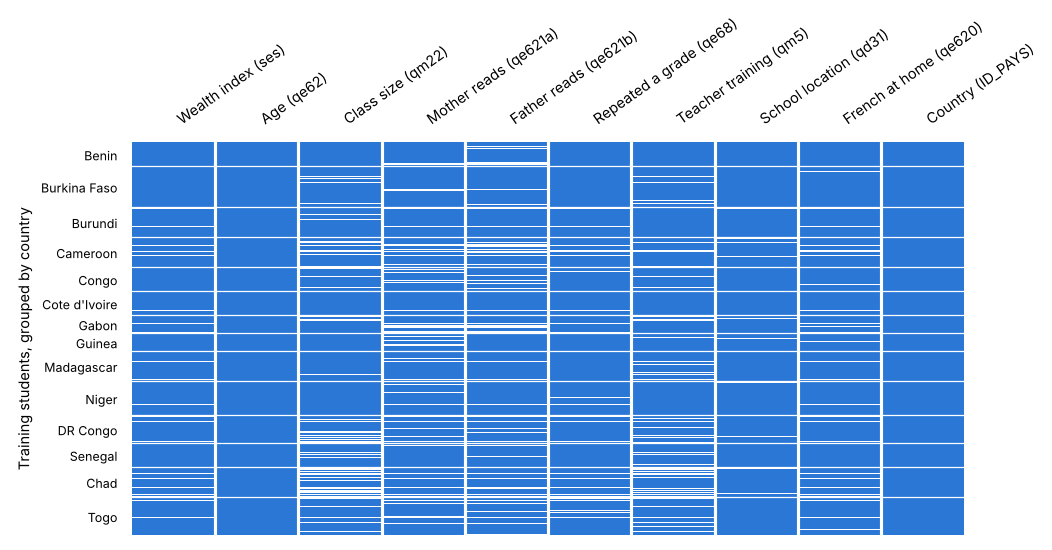

In [7]:
missing_table = pd.DataFrame({
    "missing": X_train.isna().sum(),
    "% missing": (X_train.isna().mean() * 100).round(2),
})
print(missing_table.sort_values("% missing", ascending=False))
print(f"Complete training rows: {X_train.notna().all(axis=1).sum():,} of {len(X_train):,}")

country_names = tf.COUNTRY_NAMES
ordered = X_train.sort_values("ID_PAYS", kind="stable")
ax = msno.matrix(ordered.rename(columns=LABELS), color=(0.165, 0.47, 0.84), sparkline=False,
                 fontsize=7, figsize=(TWO_COL, 3.4), label_rotation=35)
ends = ordered["ID_PAYS"].value_counts().sort_index().cumsum()
starts = ends.shift(fill_value=0)
ax.set_yticks((starts + ends) / 2, [country_names[c] for c in ends.index], fontsize=6)
for edge in ends.values[:-1]:
    ax.axhline(edge, color="white", lw=0.6)
ax.set_ylabel("Training students, grouped by country", fontsize=7)
save(ax.get_figure(), "fig1_1_missingness_heatmap.png")
plt.show()

### Missingness mechanism checks
Little's test on the numeric features, the association between missingness and country (Cramer's V with its
chi-square p-value), and the label rate for missing versus observed rows. If the missing group does worse than every
observed answer, the value is probably missing because of something linked to achievement (MNAR suspected).

In [8]:
def littles_mcar_test(data):
    mean, cov = data.mean(), data.cov()
    d2, dof = 0.0, 0
    for pattern, part in data.groupby(data.isna().apply(tuple, axis=1)):
        observed = [c for c, miss in zip(data.columns, pattern) if not miss]
        if not observed:
            continue
        diff = (part[observed].mean() - mean[observed]).values
        d2 += len(part) * diff @ np.linalg.inv(cov.loc[observed, observed].values) @ diff
        dof += len(observed)
    dof -= data.shape[1]
    return d2, dof, stats.chi2.sf(d2, dof)

chi2, dof, p = littles_mcar_test(X_train[tf.NUMERIC_FEATURES])
print(f"Little's MCAR test: chi2 = {chi2:.1f}, df = {dof}, p = {p:.1e}")

rows = []
for col in tf.NUMERIC_FEATURES + tf.BINARY_FEATURES + tf.ORDINAL_FEATURES:
    miss = X_train[col].isna()
    table = pd.crosstab(miss, X_train["ID_PAYS"])
    chi, p_country, _, _ = stats.chi2_contingency(table)
    rows.append({
        "feature": col,
        "% missing": round(miss.mean() * 100, 1),
        "Cramer V (country)": round(np.sqrt(chi / (table.values.sum() * (min(table.shape) - 1))), 3),
        "p (country)": f"{p_country:.1e}",
        "% below | missing": round(y_train[miss].mean() * 100, 1),
        "% below | observed": round(y_train[~miss].mean() * 100, 1),
    })
mechanism = pd.DataFrame(rows).set_index("feature")
mechanism

Little's MCAR test: chi2 = 329.5, df = 9, p = 1.4e-65


,% missing,Cramer V (country),p (country),% below | missing,% below | observed
feature,,,,,
ses,3.9,0.133,5.1e-183,79.7,62.4
qe62,0.3,0.068,6.9e-42,77.0,63.0
qm22,14.0,0.238,0.0e+00,66.6,62.5
qe621a,10.9,0.163,5.1e-277,68.5,62.4
qe621b,11.6,0.171,2.8e-308,68.1,62.4
qe68,6.5,0.153,4.3e-245,75.7,62.2
qm5,13.3,0.213,0.0e+00,68.5,62.2
qd31,3.5,0.136,2.5e-191,55.6,63.3
qe620,6.4,0.175,0.0e+00,82.6,61.7


### Figure 1.2: Target distribution
Left: class balance in the train and test sets. Right: share below the minimum per country, unweighted and weighted
by `rwgt0`. The weighted share is the population estimate.

               unweighted  weighted
Gabon                29.9      33.1
Senegal              36.0      34.3
Burkina Faso         39.4      36.8
Burundi              38.5      38.5
Benin                51.8      48.8
Togo                 66.2      63.4
Congo                68.3      67.4
Cameroon             63.2      67.7
Guinea               70.2      67.9
Niger                77.1      78.0
Madagascar           82.3      79.1
DR Congo             83.4      82.0
Cote d'Ivoire        84.2      83.4
Chad                 87.6      89.2

Largest gap between weighted and unweighted share: 4.5 points


saved figures/fig1_2_target_distribution.png


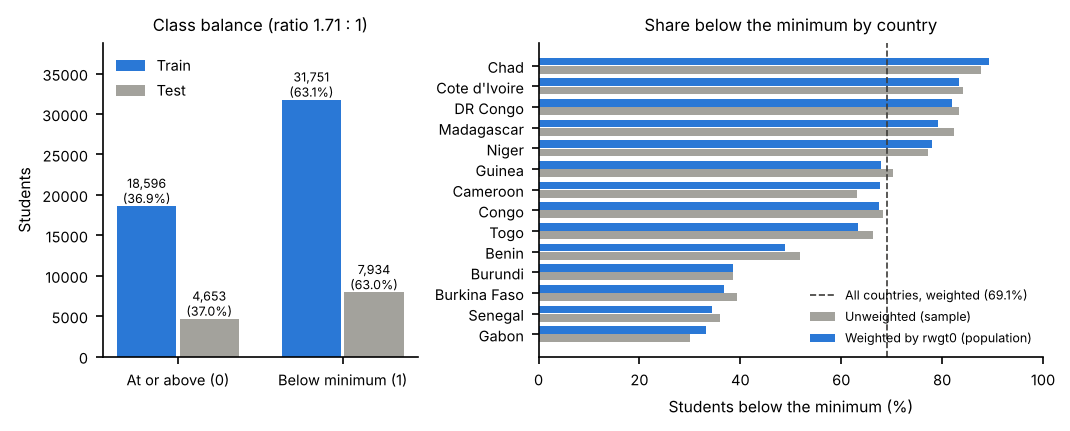

In [9]:
counts = pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).loc[[0, 1]]
by_country = pd.DataFrame({
    "unweighted": y.groupby(raw["ID_PAYS"]).mean(),
    "weighted": pd.Series({c: np.average(y[raw["ID_PAYS"] == c], weights=weight[raw["ID_PAYS"] == c])
                           for c in sorted(raw["ID_PAYS"].unique())}),
}).mul(100)
by_country.index = [country_names[c] for c in by_country.index]
by_country = by_country.sort_values("weighted")
print(by_country.round(1))
print(f"\nLargest gap between weighted and unweighted share: {(by_country.weighted - by_country.unweighted).abs().max():.1f} points")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TWO_COL, 2.9), gridspec_kw={"width_ratios": [1, 1.6]})
x = np.arange(2)
for i, (name, colour) in enumerate([("Train", BLUE), ("Test", GRAY)]):
    bars = ax1.bar(x + (i - 0.5) * 0.38, counts[name], width=0.36, color=colour, label=name)
    for bar, n in zip(bars, counts[name]):
        ax1.text(bar.get_x() + bar.get_width() / 2, n + 400, f"{n:,}\n({n / counts[name].sum():.1%})",
                 ha="center", fontsize=6)
ax1.set_xticks(x, ["At or above (0)", "Below minimum (1)"])
ax1.set_ylabel("Students")
ax1.set_ylim(0, counts.values.max() * 1.22)
ax1.set_title(f"Class balance (ratio {y_train.mean() / (1 - y_train.mean()):.2f} : 1)")
ax1.legend(frameon=False, loc="upper left")

pos = np.arange(len(by_country))
ax2.barh(pos - 0.2, by_country["unweighted"], height=0.38, color=GRAY, label="Unweighted (sample)")
ax2.barh(pos + 0.2, by_country["weighted"], height=0.38, color=BLUE, label="Weighted by rwgt0 (population)")
ax2.set_yticks(pos, by_country.index)
ax2.axvline(np.average(y, weights=weight) * 100, color=DARK, ls="--", lw=0.8,
            label=f"All countries, weighted ({np.average(y, weights=weight):.1%})")
ax2.set_xlabel("Students below the minimum (%)")
ax2.set_xlim(0, 100)
ax2.set_title("Share below the minimum by country")
ax2.legend(frameon=False, loc="lower right", fontsize=6)
fig.tight_layout()
save(fig, "fig1_2_target_distribution.png")
plt.show()

## 6. Outliers

`Winsorizer` learns its bounds on `X_train`: mean +/- 3 SD for the near-normal wealth index, and 1.5 x IQR for age and
class size (skewed). Values outside the bounds are capped, never deleted. Capping is used only in the logistic
regression pipeline; the gradient boosting pipeline keeps the original values.

In [10]:
capper = tf.Winsorizer().fit(X_train[tf.NUMERIC_FEATURES])
capped = capper.transform(X_train[tf.NUMERIC_FEATURES])

rows = {}
for c in tf.NUMERIC_FEATURES:
    v = X_train[c].dropna()
    q1, q3 = v.quantile([0.25, 0.75])
    rows[c] = {
        "mean": v.mean(), "SD": v.std(), "skewness": v.skew(),
        "excess kurtosis": v.kurt(), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
        "lower bound": capper.bounds_[c][0], "upper bound": capper.bounds_[c][1],
        "values capped": capper.n_capped_[c], "% of observed": capper.n_capped_[c] / len(v) * 100,
    }
outliers = pd.DataFrame(rows).T.astype(float).round(2)
outliers.insert(0, "rule", [tf.OUTLIER_RULES[c] for c in outliers.index])
print(f"Rows removed: {len(X_train) - len(capped)}")
outliers

Rows removed: 0


,rule,mean,SD,skewness,excess kurtosis,Q1,Q3,IQR,lower bound,upper bound,values capped,% of observed
ses,zscore,48.87,9.92,-0.09,-0.56,42.19,56.4,14.21,19.1,78.64,34.0,0.07
qe62,iqr,12.85,1.71,0.64,1.51,12.00,14.0,2.00,9.0,17.00,540.0,1.08
qm22,iqr,39.31,22.98,3.32,26.82,25.00,48.0,23.00,-9.5,82.50,1680.0,3.88


saved figures/fig2_1_outlier_boxplots.png


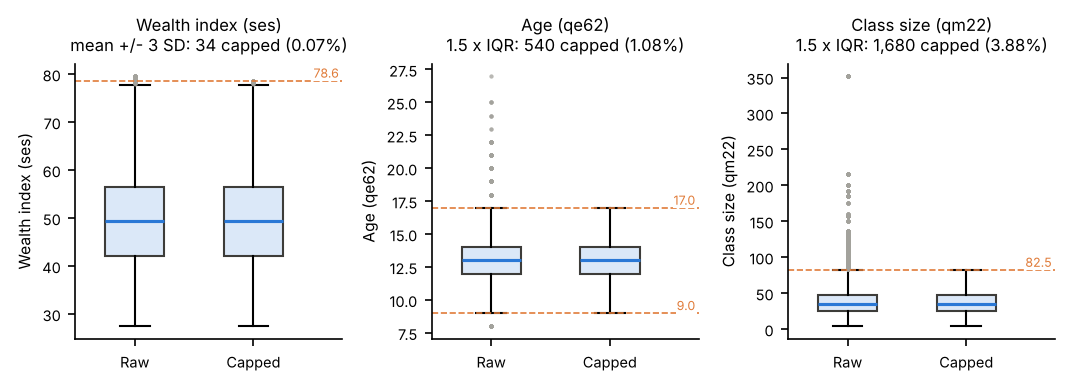

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(TWO_COL, 2.6))
for ax, col in zip(axes, tf.NUMERIC_FEATURES):
    data = [X_train[col].dropna(), capped[col].dropna()]
    ax.boxplot(data, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#dbe8f8", color=DARK), medianprops=dict(color=BLUE, linewidth=1.5),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=GRAY, markeredgecolor="none", alpha=0.5))
    lo, hi = capper.bounds_[col]
    for bound in (lo, hi):
        if data[0].min() <= bound <= data[0].max():
            ax.axhline(bound, color=ORANGE, ls="--", lw=0.8)
            ax.text(2.72, bound, f"{bound:.1f}", color=ORANGE, fontsize=6, va="bottom", ha="right",
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3))
    ax.set_xticks([1, 2], ["Raw", "Capped"])
    ax.set_xlim(0.5, 2.75)
    ax.set_ylabel(LABELS[col])
    rule = "mean +/- 3 SD" if tf.OUTLIER_RULES[col] == "zscore" else "1.5 x IQR"
    ax.set_title(f"{LABELS[col]}\n{rule}: {capper.n_capped_[col]:,} capped "
                 f"({capper.n_capped_[col] / data[0].size:.2%})")
fig.tight_layout()
save(fig, "fig2_1_outlier_boxplots.png")
plt.show()

## 7. Correlation and multicollinearity

Computed on the imputed training data. Two candidate columns that were excluded from the feature set are added so
the rule can be seen working: students present (`qm21`) and birth year (`qe61y`).
Rule: flag pairs with |Spearman rho| >= 0.85, then drop the feature with the lower mutual information with the label.
If the two are within 0.001 (a tie), drop the one with more missing values; if that also ties, keep the selected feature.

In [12]:
imputer = tf.CountryImputer().fit(X_train)
X_train_imp = imputer.transform(X_train)[tf.FEATURES]

candidates_raw = clean.iloc[train_idx][["qm21", "qe61y"]].apply(pd.to_numeric, errors="coerce")
candidates = candidates_raw.fillna(candidates_raw.median())
corr_frame = pd.concat([X_train_imp.drop(columns="ID_PAYS"), candidates], axis=1)

rho = corr_frame.corr(method="spearman")
pairs = [
    (a, b, rho.loc[a, b])
    for i, a in enumerate(rho.columns) for b in rho.columns[i + 1:]
    if abs(rho.loc[a, b]) >= 0.85
]
print("Pairs with |rho| >= 0.85:")
for a, b, r in pairs:
    print(f"  {a} - {b}: rho = {r:.3f}, Pearson r = {corr_frame[a].corr(corr_frame[b]):.3f}")

mi_pairs = mutual_info_classif(corr_frame, y_train, discrete_features=[c != "ses" for c in corr_frame.columns], random_state=0)
mi_lookup = dict(zip(corr_frame.columns, mi_pairs))
missing_lookup = pd.concat([X_train, clean.iloc[train_idx][["qm21", "qe61y"]]], axis=1).isna().mean()

def column_to_drop(a, b, tol=0.001):
    # 1) lower mutual information, 2) more missing values, 3) keep the selected feature
    if abs(mi_lookup[a] - mi_lookup[b]) >= tol:
        return min((a, b), key=lambda c: mi_lookup[c])
    if abs(missing_lookup[a] - missing_lookup[b]) >= 0.001:
        return max((a, b), key=lambda c: missing_lookup[c])
    return b if a in tf.FEATURES else a

to_drop = []
for a, b, _ in pairs:
    dropped = column_to_drop(a, b)
    to_drop.append(dropped)
    print(f"{a} vs {b}: MI {mi_lookup[a]:.4f} vs {mi_lookup[b]:.4f}, "
          f"missing {missing_lookup[a]:.2%} vs {missing_lookup[b]:.2%} -> drop {dropped}")

Pairs with |rho| >= 0.85:
  qe62 - qe61y: rho = -1.000, Pearson r = -1.000
  qm22 - qm21: rho = 0.887, Pearson r = 0.773


qe62 vs qe61y: MI 0.0075 vs 0.0075, missing 0.28% vs 0.28% -> drop qe61y
qm22 vs qm21: MI 0.0197 vs 0.0138, missing 14.05% vs 14.86% -> drop qm21


saved figures/fig3_1_correlation_matrix.png


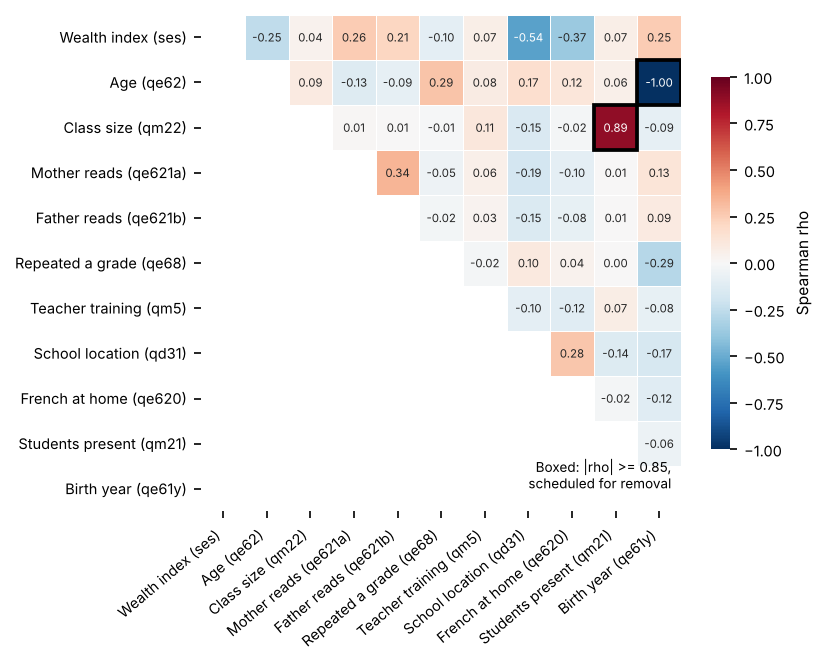

In [13]:
mask = np.tril(np.ones_like(rho, dtype=bool))
fig, ax = plt.subplots(figsize=(TWO_COL * 0.72, 4.3))
sns.heatmap(rho, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 5.5}, linewidths=0.4, cbar_kws={"label": "Spearman rho", "shrink": 0.75}, ax=ax,
            xticklabels=[LABELS[c] for c in rho.columns], yticklabels=[LABELS[c] for c in rho.columns])
for a, b, _ in pairs:
    i, j = sorted([rho.columns.get_loc(a), rho.columns.get_loc(b)])
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", lw=1.8))
ax.text(0.98, 0.04, "Boxed: |rho| >= 0.85,\nscheduled for removal", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=6.5)
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
save(fig, "fig3_1_correlation_matrix.png")
plt.show()

In [14]:
def vif_table(frame):
    data = add_constant(frame)
    with np.errstate(divide="ignore"):
        values = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return pd.Series(values, index=data.columns).drop("const")

before = vif_table(pd.concat([X_train_imp.drop(columns="ID_PAYS"), candidates], axis=1))
after_frame = pd.concat([
    X_train_imp.drop(columns="ID_PAYS"),
    pd.get_dummies(X_train_imp["ID_PAYS"].astype(int), prefix="country", drop_first=True).astype(float),
], axis=1)
after = vif_table(after_frame)
features_after = after.drop(after.filter(like="country").index)

vif = pd.DataFrame({"VIF with candidates": before, "VIF after removal (+ country dummies)": features_after})
print(f"Highest VIF after removal, features: {features_after.max():.2f}")
print(f"Highest VIF after removal, country dummies: {after.filter(like='country').max():.2f}")
print("Any VIF > 10 after removal:", bool((after > 10).any()))
vif.sort_values("VIF with candidates", ascending=False).round(2)

Highest VIF after removal, features: 1.87
Highest VIF after removal, country dummies: 2.59
Any VIF > 10 after removal: False


,VIF with candidates,VIF after removal (+ country dummies)
qe62,1946.18,1.30
qe61y,1945.61,NaN
qm22,2.53,1.12
qm21,2.50,NaN
ses,1.62,1.87
qd31,1.47,1.60
qe621a,1.19,1.45
qe620,1.17,1.43
qe621b,1.16,1.19
qe68,1.08,1.18


saved figures/fig3_2_collinear_scatterplots.png


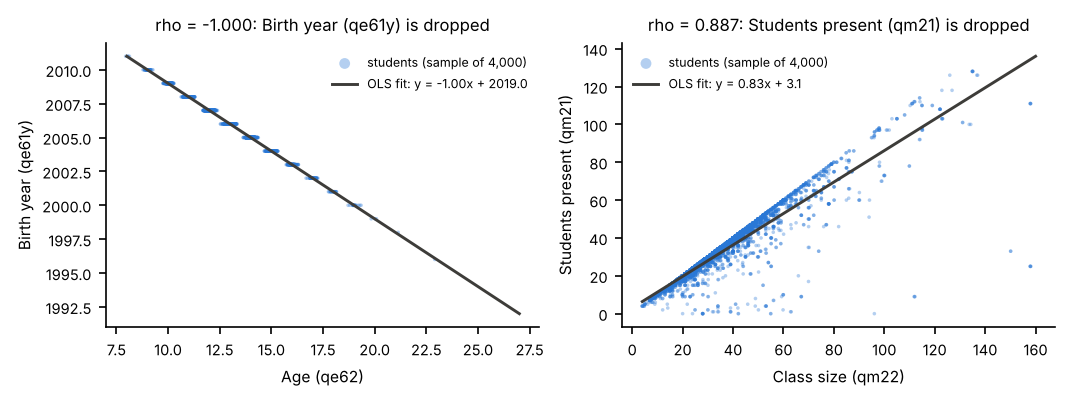

In [15]:
observed = pd.concat([X_train[tf.NUMERIC_FEATURES], candidates_raw], axis=1)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(pairs), figsize=(TWO_COL, 2.7))
for ax, (a, b, r) in zip(np.atleast_1d(axes), pairs):
    both = observed[[a, b]].dropna()
    shown = both.sample(min(4000, len(both)), random_state=0)
    ax.scatter(shown[a] + rng.normal(0, 0.12, len(shown)), shown[b], s=3, alpha=0.35, color=BLUE,
               edgecolors="none", label=f"students (sample of {len(shown):,})")
    slope, intercept = np.polyfit(both[a], both[b], 1)
    xs = np.linspace(both[a].min(), both[a].max(), 100)
    ax.plot(xs, slope * xs + intercept, color=DARK, lw=1.4,
            label=f"OLS fit: y = {slope:.2f}x {'+' if intercept >= 0 else '-'} {abs(intercept):.1f}")
    ax.set_xlabel(LABELS[a])
    ax.set_ylabel(LABELS[b])
    ax.set_title(f"rho = {r:.3f}: {LABELS[b]} is dropped")
    ax.legend(frameon=False, loc="best", fontsize=6, markerscale=3)
fig.tight_layout()
save(fig, "fig3_2_collinear_scatterplots.png")
plt.show()

### Figure 3.3: Feature-to-target ranking
Mutual information is used because it works the same way for continuous, ordinal and nominal features
(country has 14 unordered categories, so a correlation coefficient would not be meaningful for it).

saved figures/fig3_3_target_importance.png


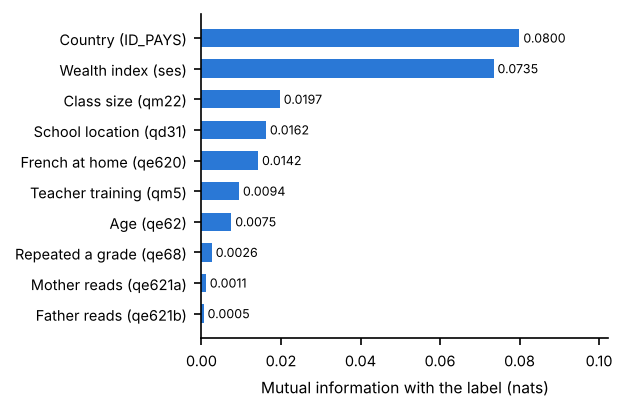

ID_PAYS    0.0800
ses        0.0735
qm22       0.0197
qd31       0.0162
qe620      0.0142
qm5        0.0094
qe62       0.0075
qe68       0.0026
qe621a     0.0011
qe621b     0.0005
dtype: float64

In [16]:
mi = mutual_info_classif(X_train_imp, y_train, discrete_features=[c != "ses" for c in X_train_imp.columns], random_state=0)
importance = pd.Series(mi, index=X_train_imp.columns).sort_values()

fig, ax = plt.subplots(figsize=(ONE_COL, 2.8))
ax.barh([LABELS[c] for c in importance.index], importance.values, color=BLUE, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=6)
ax.set_xlabel("Mutual information with the label (nats)")
ax.set_xlim(0, importance.max() * 1.28)
save(fig, "fig3_3_target_importance.png")
plt.show()
importance.sort_values(ascending=False).round(4)

## 8. Transformations

Class size is strongly right-skewed. The grid shows the four stages on the observed training values:
raw, log(1 + x), Min-Max of the log, and standardized log. The pipeline uses log then standardization
for logistic regression; Min-Max is shown for comparison only.

                         mean      SD    min      max  skewness  excess kurtosis
Raw                    39.313  22.982  4.000  352.000     3.319           26.815
Log(1 + x)              3.570   0.499  1.609    5.866    -0.021            0.717
Min-Max (of log)        0.461   0.117  0.000    1.000    -0.021            0.717
Standardized (of log)   0.000   1.000 -3.928    4.599    -0.021            0.717


saved figures/fig4_1_transformation_grid.png


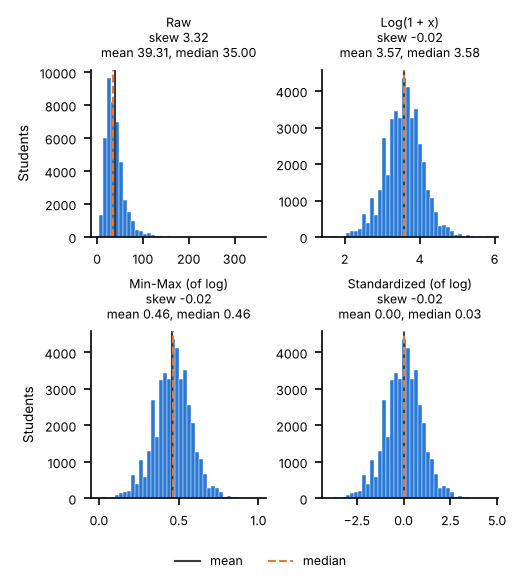

In [17]:
size = X_train["qm22"].dropna()
stages = {
    "Raw": size,
    "Log(1 + x)": np.log1p(size),
    "Min-Max (of log)": pd.Series(MinMaxScaler().fit_transform(np.log1p(size).to_frame()).ravel()),
    "Standardized (of log)": pd.Series(StandardScaler().fit_transform(np.log1p(size).to_frame()).ravel()),
}
stage_stats = pd.DataFrame({
    name: {"mean": v.mean(), "SD": v.std(), "min": v.min(), "max": v.max(),
           "skewness": v.skew(), "excess kurtosis": v.kurt()}
    for name, v in stages.items()
}).T
print(stage_stats.round(3))

fig, axes = plt.subplots(2, 2, figsize=(ONE_COL, 3.8))
for ax, (name, values) in zip(axes.ravel(), stages.items()):
    ax.hist(values, bins=40, color=BLUE, edgecolor="white", linewidth=0.2)
    ax.axvline(values.mean(), color=DARK, lw=1)
    ax.axvline(values.median(), color=ORANGE, lw=1, ls="--")
    ax.set_title(f"{name}\nskew {values.skew():.2f}\nmean {values.mean():.2f}, median {values.median():.2f}",
                 fontsize=6)
    ax.tick_params(labelsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel("Students", fontsize=6.5)
fig.legend([plt.Line2D([], [], color=DARK, lw=1), plt.Line2D([], [], color=ORANGE, lw=1, ls="--")],
           ["mean", "median"], loc="lower center", ncol=2, frameon=False, fontsize=6, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(h_pad=0.6, w_pad=0.6, rect=(0, 0.04, 1, 1))
save(fig, "fig4_1_transformation_grid.png")
plt.show()

## 9. The pipeline

`build_preprocessor` returns a scikit-learn `Pipeline` with a `ColumnTransformer` inside:

| Step | Logistic regression | Gradient boosting (XGBoost) |
|---|---|---|
| Winsorizer (bounds from observed training values) | yes | no |
| CountryImputer (country mean / median / mode + missing flags) | yes | yes |
| Numeric: log(1 + x) for class size, StandardScaler | yes | passthrough |
| Binary: StandardScaler | yes | passthrough |
| Ordinal: OrdinalEncoder (+ StandardScaler) | yes | encoder only |
| Missing flags | passthrough | passthrough |
| Country: OneHotEncoder | yes | yes |

Each preprocessor is fitted on `X_train` only, then applied to `X_test`.

In [18]:
pre_logreg = pb.build_preprocessor("logreg").fit(X_train)
pre_xgb = pb.build_preprocessor("xgboost").fit(X_train)

Xtr_lr, Xte_lr = pre_logreg.transform(X_train), pre_logreg.transform(X_test)
Xtr_xgb, Xte_xgb = pre_xgb.transform(X_train), pre_xgb.transform(X_test)

check = pd.DataFrame({
    "rows": [len(Xtr_lr), len(Xte_lr), len(Xtr_xgb), len(Xte_xgb)],
    "columns": [Xtr_lr.shape[1], Xte_lr.shape[1], Xtr_xgb.shape[1], Xte_xgb.shape[1]],
    "NaN left": [int(d.isna().sum().sum()) for d in (Xtr_lr, Xte_lr, Xtr_xgb, Xte_xgb)],
}, index=["logreg train", "logreg test", "xgboost train", "xgboost test"])
print(check)
print("\nOutput columns:", list(Xtr_lr.columns))

                rows  columns  NaN left
logreg train   50347       32         0
logreg test    12587       32         0
xgboost train  50347       32         0
xgboost test   12587       32         0

Output columns: ['ses', 'qe62', 'qm22', 'qe621a', 'qe621b', 'qe68', 'qm5', 'qd31', 'qe620', 'ses_missing', 'qe62_missing', 'qm22_missing', 'qe621a_missing', 'qe621b_missing', 'qe68_missing', 'qm5_missing', 'qd31_missing', 'qe620_missing', 'ID_PAYS_1.0', 'ID_PAYS_2.0', 'ID_PAYS_3.0', 'ID_PAYS_4.0', 'ID_PAYS_5.0', 'ID_PAYS_6.0', 'ID_PAYS_7.0', 'ID_PAYS_8.0', 'ID_PAYS_9.0', 'ID_PAYS_10.0', 'ID_PAYS_11.0', 'ID_PAYS_12.0', 'ID_PAYS_13.0', 'ID_PAYS_14.0']


In [19]:
num_cols = tf.NUMERIC_FEATURES + tf.BINARY_FEATURES + tf.ORDINAL_FEATURES
print("Logistic regression, training set (should be mean 0, SD 1):")
print(Xtr_lr[num_cols].agg(["mean", "std"]).round(3))
print("\nSame transformation on the test set (close to, but not exactly, 0 and 1):")
print(Xte_lr[num_cols].agg(["mean", "std"]).round(3))

Logistic regression, training set (should be mean 0, SD 1):
      ses  qe62  qm22  qe621a  qe621b  qe68  qm5  qd31  qe620
mean -0.0   0.0   0.0    -0.0     0.0   0.0  0.0  -0.0    0.0
std   1.0   1.0   1.0     1.0     1.0   1.0  1.0   1.0    1.0

Same transformation on the test set (close to, but not exactly, 0 and 1):
        ses   qe62   qm22  qe621a  qe621b   qe68    qm5   qd31  qe620
mean -0.015 -0.010  0.002  -0.013  -0.005 -0.018 -0.040 -0.001  0.030
std   1.018  1.011  1.022   1.001   1.002  1.002  0.992  1.022  0.996


In [20]:
imp = pre_logreg.named_steps["impute"]
cap = pre_logreg.named_steps["cap"]
scaler = pre_logreg.named_steps["columns"].named_transformers_["numeric"].named_steps["scale"]
print("Capping bounds learned from X_train:", {c: (round(float(lo), 2), round(float(hi), 2)) for c, (lo, hi) in cap.bounds_.items()})
print("Scaler means learned from X_train (class size on the log scale):",
      {c: round(float(m), 3) for c, m in zip(tf.NUMERIC_FEATURES, scaler.mean_)})
print("\nFill values learned from the training set:")
pd.DataFrame({
    "Chad": imp.by_group_[13.0], "Senegal": imp.by_group_[12.0], "all countries": imp.global_,
}).round(2)

Capping bounds learned from X_train: {'ses': (19.1, 78.64), 'qe62': (9.0, 17.0), 'qm22': (-9.5, 82.5)}
Scaler means learned from X_train (class size on the log scale): {'ses': 48.816, 'qe62': 12.829, 'qm22': 3.571}

Fill values learned from the training set:


,Chad,Senegal,all countries
ses,45.1,55.1,48.87
qe62,13.0,12.0,13.00
qm22,42.0,34.0,35.00
qe621a,0.0,0.0,1.00
qe621b,1.0,1.0,1.00
qe68,1.0,1.0,1.00
qm5,3.0,3.0,3.00
qd31,3.0,3.0,1.00
qe620,3.0,3.0,3.00


## 10. Leakage check with cross-validation and survey weights

Each full pipeline (preprocessing + model) is cloned and re-fitted inside every training fold of the same
school-grouped folds, so the validation fold never contributes to imputation values, capping bounds or scaling.

Four set-ups are compared:
- logistic regression with balanced class weights and no survey weights (the original strategy);
- elastic-net logistic regression (L1 ratio 0.5) fitted with survey weights;
- XGBoost fitted with survey weights, on the unscaled gradient boosting matrix;
- CatBoost fitted with survey weights, with country kept as one categorical column instead of 14 one-hot columns.

With survey weights, each student's loss is weighted by `rwgt0` (rescaled to mean 1) times a class-balance factor.
Metrics are reported unweighted (sample) and weighted by `rwgt0` (population estimate). This is a pipeline check,
not model selection.

In [21]:
setups = {
    "LogReg, balanced, unweighted": (pb.build_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=2000), model="logreg"), False),
    "Elastic-net LogReg, survey-weighted": (pb.build_pipeline(
        LogisticRegression(l1_ratio=0.5, solver="saga", C=1.0, max_iter=3000, random_state=0), model="logreg"), True),
    "XGBoost, survey-weighted": (pb.build_pipeline(
        XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                      tree_method="hist", random_state=0, n_jobs=4), model="xgboost"), True),
    "CatBoost, survey-weighted": (pb.build_pipeline(
        CatBoostClassifier(iterations=500, depth=6, learning_rate=0.08, random_seed=0, thread_count=4, verbose=0),
        model="catboost"), True),
}
fit_params = {"CatBoost, survey-weighted": {"model__cat_features": [tf.COUNTRY]}}

oof = {}
rows = []
for name, (pipeline, weighted) in setups.items():
    prob, fold = ev.out_of_fold_proba(pipeline, X_train, y_train, groups_train, strata_train,
                                      survey_weight=w_train if weighted else None,
                                      fit_params=fit_params.get(name))
    oof[name] = prob
    for metric_weight, label in [(None, "sample"), (w_train.values, "rwgt0")]:
        scores = ev.classification_scores(y_train.values, prob, metric_weight)
        rows.append({"set-up": name, "metrics": label, **scores})
cv_table = pd.DataFrame(rows).set_index(["set-up", "metrics"])
cv_table.round(3)

recall     f1  balanced_accuracy  roc_auc
set-up                              metrics                                           
LogReg, balanced, unweighted        sample    0.710  0.762              0.724    0.777
                                    rwgt0     0.816  0.822              0.719    0.765
Elastic-net LogReg, survey-weighted sample    0.634  0.723              0.713    0.774
                                    rwgt0     0.760  0.798              0.717    0.763
XGBoost, survey-weighted            sample    0.661  0.738              0.718    0.782
                                    rwgt0     0.767  0.799              0.713    0.769
CatBoost, survey-weighted           sample    0.663  0.738              0.718    0.778
                                    rwgt0     0.772  0.802              0.713    0.762

In [22]:
print("Per-fold scores, elastic-net LogReg, weighted by rwgt0:")
ev.scores_by_fold(y_train.values, oof["Elastic-net LogReg, survey-weighted"], fold, w_train.values).round(3)

Per-fold scores, elastic-net LogReg, weighted by rwgt0:


,recall,f1,balanced_accuracy,roc_auc
fold 1,0.765,0.802,0.717,0.759
fold 2,0.743,0.789,0.724,0.773
fold 3,0.784,0.810,0.709,0.734
fold 4,0.732,0.789,0.729,0.790
fold 5,0.776,0.800,0.705,0.758
mean,0.760,0.798,0.717,0.763


## 11. Imputation sensitivity checks

Two alternatives to within-country imputation, run with the same folds and survey weights:
- iterative (MICE-style) imputation: each feature with gaps is predicted from the other features and the country
  dummies, for the elastic-net logistic regression;
- no imputation for XGBoost: gaps stay `NaN` and XGBoost learns a default branch direction for them.

In [23]:
sensitivity = {
    "Elastic-net LogReg, within-country imputation": oof["Elastic-net LogReg, survey-weighted"],
    "XGBoost, within-country imputation": oof["XGBoost, survey-weighted"],
}
alternatives = {
    "Elastic-net LogReg, iterative imputation": pb.build_pipeline(
        LogisticRegression(l1_ratio=0.5, solver="saga", C=1.0, max_iter=3000, random_state=0), model="logreg", imputer="iterative"),
    "XGBoost, native missing values": pb.build_pipeline(
        XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                      tree_method="hist", random_state=0, n_jobs=4), model="xgboost", imputer="none"),
}
for name, pipeline in alternatives.items():
    sensitivity[name], _ = ev.out_of_fold_proba(pipeline, X_train, y_train, groups_train, strata_train,
                                                survey_weight=w_train)
pd.DataFrame({name: ev.classification_scores(y_train.values, prob, w_train.values)
              for name, prob in sensitivity.items()}).T.round(3)

,recall,f1,balanced_accuracy,roc_auc
"Elastic-net LogReg, within-country imputation",0.760,0.798,0.717,0.763
"XGBoost, within-country imputation",0.767,0.799,0.713,0.769
"Elastic-net LogReg, iterative imputation",0.759,0.798,0.717,0.764
"XGBoost, native missing values",0.769,0.801,0.713,0.764


## 12. Students nested in schools

Students are nested in schools, and schools in countries. A two-level random-intercept model (statsmodels `MixedLM`,
school intercepts) splits the variance of the label into a between-school and a within-school part. The intraclass
correlation (ICC) is the between-school share. It is estimated with no predictors, with country fixed effects, and with
country plus all pipeline features. It is a linear probability model, used here to describe the structure, not to predict.

The second check repeats the XGBoost cross-validation with folds that ignore schools, to measure how optimistic the
scores would be if classmates were split across training and validation.

In [24]:
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

country_cols = Xtr_lr.filter(like="ID_PAYS").columns
designs = {
    "no predictors": None,
    "country": Xtr_lr[country_cols[1:]],
    "country + features": Xtr_lr.drop(columns=country_cols[:1]),
}
rows = {}
for name, exog in designs.items():
    exog = np.ones((len(y_train), 1)) if exog is None else sm.add_constant(exog.values)
    fit = sm.MixedLM(y_train.values.astype(float), exog, groups=groups_train.values).fit(reml=True)
    between, within = float(np.asarray(fit.cov_re)[0, 0]), float(fit.scale)
    rows[name] = {"between-school variance": between, "within-school variance": within,
                  "ICC": between / (between + within)}
icc_table = pd.DataFrame(rows).T
print(icc_table.round(4))
print(f"\nShare of the between-school variance (after country) explained by the features: "
      f"{1 - icc_table.loc['country + features', 'between-school variance'] / icc_table.loc['country', 'between-school variance']:.1%}")

xgb_pipeline = setups["XGBoost, survey-weighted"][0]
prob_random = np.zeros(len(X_train))
for fit_idx, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, strata_train):
    model = clone(xgb_pipeline).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx],
                                    model__sample_weight=ev.fit_weights(y_train.iloc[fit_idx], w_train.iloc[fit_idx]))
    prob_random[val_idx] = model.predict_proba(X_train.iloc[val_idx])[:, 1]
pd.DataFrame({
    "folds grouped by school": ev.classification_scores(y_train.values, oof["XGBoost, survey-weighted"], w_train.values),
    "folds ignoring schools": ev.classification_scores(y_train.values, prob_random, w_train.values),
}).T.round(3)

                    between-school variance  within-school variance     ICC
no predictors                        0.1152                  0.1168  0.4966
country                              0.0807                  0.1168  0.4085
country + features                   0.0705                  0.1151  0.3797

Share of the between-school variance (after country) explained by the features: 12.6%


,recall,f1,balanced_accuracy,roc_auc
folds grouped by school,0.767,0.799,0.713,0.769
folds ignoring schools,0.790,0.834,0.776,0.852


## 13. Borderline students

Scores for students whose five plausible values disagree (borderline) and for students whose five values agree,
using the out-of-fold probabilities above. The same predictions are also scored against each of the five
per-plausible-value labels and averaged, so the result does not depend on the majority-vote label alone. `mean |p - 0.5|` measures how far predictions are from the decision
boundary: lower means less confident.

In [25]:
border_train = borderline.iloc[train_idx].values
votes_train = votes.iloc[train_idx].values
rows = []
for name, prob in oof.items():
    for group, mask in [("borderline", border_train), ("consistent", ~border_train)]:
        scores = ev.classification_scores(y_train.values[mask], prob[mask], w_train.values[mask])
        rows.append({"set-up": name, "students": group, "n": int(mask.sum()), **scores,
                     "mean |p - 0.5|": np.abs(prob[mask] - 0.5).mean()})
border_table = pd.DataFrame(rows).set_index(["set-up", "students"])
print(border_table.round(3))

labels_pv_train = tf.label_per_plausible_value(raw).iloc[train_idx]
pv_scores = pd.DataFrame({
    name: pd.DataFrame([ev.classification_scores(labels_pv_train[c].values, prob, w_train.values)
                        for c in labels_pv_train.columns]).mean()
    for name, prob in oof.items()
}).T
print("\nScores against each of the five per-plausible-value labels, averaged (weighted by rwgt0):")
print(pv_scores.round(3))

mean_prob = pd.DataFrame({name: pd.Series(prob).groupby(votes_train).mean() for name, prob in oof.items()})
mean_prob.index.name = "plausible values below cutoff"
print("\nMean predicted probability of being below the minimum:")
mean_prob.round(3)

                                                    n  recall     f1  balanced_accuracy  roc_auc  mean |p - 0.5|
set-up                              students                                                                    
LogReg, balanced, unweighted        borderline  11210   0.611  0.598              0.560    0.574           0.192
                                    consistent  39137   0.853  0.865              0.762    0.812           0.219
Elastic-net LogReg, survey-weighted borderline  11210   0.541  0.564              0.557    0.572           0.202
                                    consistent  39137   0.800  0.841              0.759    0.810           0.210
XGBoost, survey-weighted            borderline  11210   0.558  0.571              0.556    0.568           0.228
                                    consistent  39137   0.805  0.842              0.755    0.819           0.247
CatBoost, survey-weighted           borderline  11210   0.555  0.570              0.556    0.568


Scores against each of the five per-plausible-value labels, averaged (weighted by rwgt0):
                                     recall     f1  balanced_accuracy  roc_auc
LogReg, balanced, unweighted          0.813  0.818              0.713    0.759
Elastic-net LogReg, survey-weighted   0.758  0.795              0.712    0.756
XGBoost, survey-weighted              0.764  0.795              0.707    0.762
CatBoost, survey-weighted             0.769  0.798              0.708    0.756

Mean predicted probability of being below the minimum:


,"LogReg, balanced, unweighted","Elastic-net LogReg, survey-weighted","XGBoost, survey-weighted","CatBoost, survey-weighted"
plausible values below cutoff,,,,
0,0.363,0.316,0.310,0.313
1,0.419,0.369,0.373,0.376
2,0.454,0.402,0.411,0.415
3,0.466,0.414,0.426,0.431
4,0.505,0.452,0.471,0.476
5,0.645,0.588,0.634,0.640


saved figures/fig6_1_borderline_probabilities.png


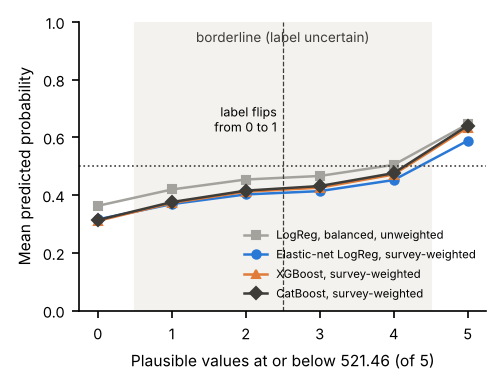

In [26]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.5))
ax.axvspan(0.5, 4.5, color="#f3f2ee", zorder=0)
ax.text(2.5, 0.93, "borderline (label uncertain)", ha="center", fontsize=6.5, color=DARK)
for (name, values), colour, marker in zip(mean_prob.items(), [GRAY, BLUE, ORANGE, DARK], ["s", "o", "^", "D"]):
    ax.plot(values.index, values.values, marker=marker, color=colour, lw=1.2, markersize=4, label=name)
ax.axhline(0.5, color=DARK, ls=":", lw=0.8)
ax.axvline(2.5, color=DARK, ls="--", lw=0.6)
ax.text(2.42, 0.62, "label flips\nfrom 0 to 1", fontsize=6, ha="right")
ax.set_xlabel("Plausible values at or below 521.46 (of 5)")
ax.set_ylabel("Mean predicted probability")
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=5.5, loc="lower right")
save(fig, "fig6_1_borderline_probabilities.png")
plt.show()

## 14. Country representation for new countries

One-hot country columns cannot describe a country that was not in the training data. Leave-one-country-out:
train on 13 countries, test on the 14th, for every country. Four country representations are compared with the
survey-weighted elastic-net logistic regression:
- none;
- one-hot (an unseen country gets all zeros);
- survey context: country averages of the answers (wealth, class size, repetition, location, French at home), no labels;
- survey context plus government spending on education (% of GDP, World Bank WDI, `data/external/country_indicators.csv`).

In [27]:
indicators = tf.load_country_indicators()
enet = LogisticRegression(l1_ratio=0.5, solver="saga", C=1.0, max_iter=3000, random_state=0)
variants = {
    "none": dict(country="none"),
    "one-hot": dict(country="onehot"),
    "survey context": dict(country="context"),
    "context + spending": dict(country="context", external=indicators),
}
loco = {name: ev.leave_one_country_out(pb.build_pipeline(enet, **kw), X_train, y_train, X_train["ID_PAYS"], w_train)
        for name, kw in variants.items()}

loco_ba = pd.DataFrame({name: r["balanced_accuracy"] for name, r in loco.items()})
loco_auc = pd.DataFrame({name: r["roc_auc"] for name, r in loco.items()})
loco_ba.index = loco_auc.index = [country_names[c] for c in loco_ba.index]
loco_summary = pd.DataFrame({"balanced accuracy": loco_ba.mean(), "ROC AUC": loco_auc.mean()})
print("Mean over the 14 held-out countries (weighted by rwgt0):")
print(loco_summary.round(3))
print("\nBalanced accuracy per held-out country:")
loco_ba.round(3)

Mean over the 14 held-out countries (weighted by rwgt0):
                    balanced accuracy  ROC AUC
none                            0.583    0.636
one-hot                         0.601    0.657
survey context                  0.563    0.656
context + spending              0.570    0.656

Balanced accuracy per held-out country:


,none,one-hot,survey context,context + spending
Benin,0.602,0.633,0.582,0.659
Burkina Faso,0.597,0.608,0.596,0.557
Burundi,0.535,0.545,0.556,0.556
Cameroon,0.647,0.658,0.523,0.546
Congo,0.631,0.633,0.603,0.624
Cote d'Ivoire,0.558,0.596,0.522,0.523
Gabon,0.560,0.570,0.556,0.584
Guinea,0.597,0.604,0.583,0.582
Madagascar,0.623,0.689,0.520,0.525
Niger,0.590,0.591,0.591,0.620


## 15. PCA diagnostic

PCA on the standardized logistic regression matrix, to see how many components hold 90% and 95% of the variance.
It is a diagnostic only. The model keeps the original features so that the prototype can explain its flags.

In [28]:
pca_input = StandardScaler().fit_transform(Xtr_lr)
pca = PCA().fit(pca_input)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
k90 = int(np.argmax(cumulative >= 0.90) + 1)
k95 = int(np.argmax(cumulative >= 0.95) + 1)
print(f"Components for 90% variance: {k90} of {len(explained)}")
print(f"Components for 95% variance: {k95} of {len(explained)}")
print(f"Components with eigenvalue > 1: {(pca.explained_variance_ > 1).sum()}")
pd.DataFrame({
    "eigenvalue": pca.explained_variance_, "% variance": explained * 100, "cumulative %": cumulative * 100,
}, index=np.arange(1, len(explained) + 1)).head(8).round(2)

Components for 90% variance: 23 of 32
Components for 95% variance: 26 of 32
Components with eigenvalue > 1: 14


,eigenvalue,% variance,cumulative %
1,3.44,10.76,10.76
2,2.61,8.16,18.92
3,1.91,5.96,24.88
4,1.62,5.05,29.93
5,1.56,4.89,34.82
6,1.41,4.41,39.23
7,1.27,3.97,43.20
8,1.19,3.72,46.91


saved figures/fig5_1_pca_scree_plot.png


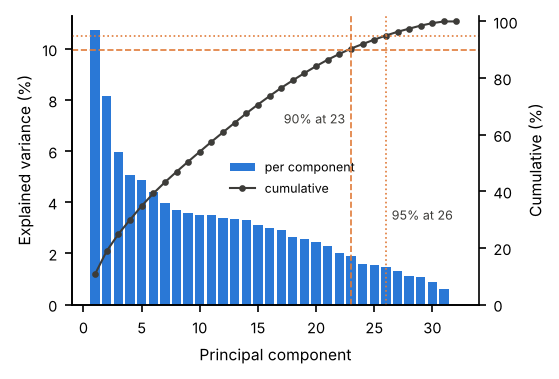

In [29]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.5))
idx = np.arange(1, len(explained) + 1)
bars = ax.bar(idx, explained * 100, color=BLUE, label="per component")
ax2 = ax.twinx()
line, = ax2.plot(idx, cumulative * 100, color=DARK, marker="o", markersize=2.2, lw=1, label="cumulative")
for level, k, style, x_text, y_text, align in [(90, k90, "--", k90 - 0.5, 64, "right"),
                                              (95, k95, ":", k95 + 0.5, 30, "left")]:
    ax2.axhline(level, color=ORANGE, ls=style, lw=0.8)
    ax2.axvline(k, color=ORANGE, ls=style, lw=0.8)
    ax2.text(x_text, y_text, f"{level}% at {k}", fontsize=6, color=DARK, ha=align)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax2.set_ylabel("Cumulative (%)")
ax2.set_ylim(0, 102)
ax2.spines["right"].set_visible(True)
ax.legend([bars, line], ["per component", "cumulative"], frameon=False, loc="center left",
          bbox_to_anchor=(0.36, 0.44), fontsize=6)
save(fig, "fig5_1_pca_scree_plot.png")
plt.show()

## 16. Save the processed data and verify the output

The processed matrices go to `data/processed/` (kept out of GitHub with the raw data).
`ID_TOT`, the school key, the survey weight `rwgt0`, gender (`qe63`, for fairness checks only), the number of
plausible values below the cutoff and the borderline flag are saved alongside for the modelling step.

In [30]:
meta = clean[["ID_TOT", "ID_PAYS", "qe63", "rwgt0"]].assign(school=groups, label=y, votes_below=votes, borderline=borderline)
labels_pv = tf.label_per_plausible_value(raw)

for name, frame, rows_idx in [
    ("X_train_logreg", Xtr_lr, train_idx), ("X_test_logreg", Xte_lr, test_idx),
    ("X_train_xgboost", Xtr_xgb, train_idx), ("X_test_xgboost", Xte_xgb, test_idx),
]:
    frame.assign(ID_TOT=raw["ID_TOT"].iloc[rows_idx].values).to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
pd.concat([meta, labels_pv], axis=1).iloc[train_idx].to_csv(PROCESSED_DIR / "train_meta.csv", index=False)
pd.concat([meta, labels_pv], axis=1).iloc[test_idx].to_csv(PROCESSED_DIR / "test_meta.csv", index=False)
print(sorted(p.name for p in PROCESSED_DIR.glob("*.csv")))

['X_test_logreg.csv', 'X_test_xgboost.csv', 'X_train_logreg.csv', 'X_train_xgboost.csv', 'test_meta.csv', 'train_meta.csv']


In [31]:
pre_cat = pb.build_preprocessor("catboost").fit(X_train)
Xtr_cat, Xte_cat = pre_cat.transform(X_train), pre_cat.transform(X_test)
verification = pd.DataFrame({
    "stage": ["Raw file", "Selected features", "Pipeline output (logreg)", "Pipeline output (xgboost)",
              "Pipeline output (catboost)"],
    "rows": [n_rows, len(X), len(Xtr_lr) + len(Xte_lr), len(Xtr_xgb) + len(Xte_xgb), len(Xtr_cat) + len(Xte_cat)],
    "columns": [n_cols, X.shape[1], Xtr_lr.shape[1], Xtr_xgb.shape[1], Xtr_cat.shape[1]],
    "missing cells": [int(audit["total_missing"].sum()), int(X.isna().sum().sum()),
                      int(Xtr_lr.isna().sum().sum() + Xte_lr.isna().sum().sum()),
                      int(Xtr_xgb.isna().sum().sum() + Xte_xgb.isna().sum().sum()),
                      int(Xtr_cat.isna().sum().sum() + Xte_cat.isna().sum().sum())],
})
print("Rows dropped at any stage:", n_rows - (len(Xtr_lr) + len(Xte_lr)))
print(f"Engineered columns: {len(num_cols)} features + {len(pb.INDICATOR_FEATURES)} missing flags + "
      f"{Xtr_lr.filter(like='ID_PAYS').shape[1]} country columns = {Xtr_lr.shape[1]}")
verification

Rows dropped at any stage: 0
Engineered columns: 9 features + 9 missing flags + 14 country columns = 32


,stage,rows,columns,missing cells
0,Raw file,62934,749,12109003
1,Selected features,62934,10,44283
2,Pipeline output (logreg),62934,32,0
3,Pipeline output (xgboost),62934,32,0
4,Pipeline output (catboost),62934,19,0
